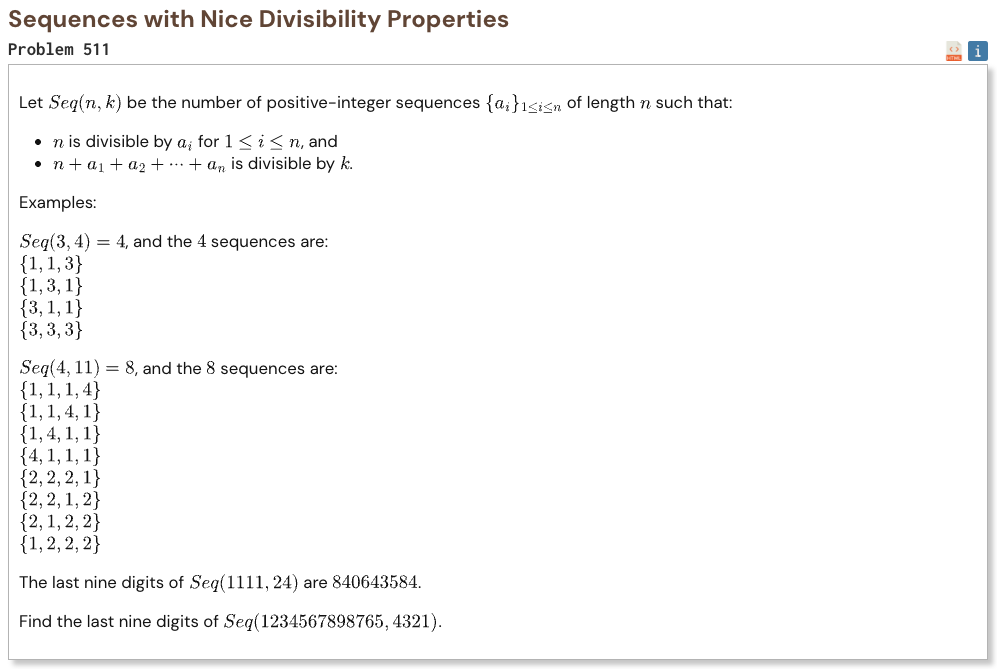

## Initial approach

- find all positive divisors of the given number
- group these divisors by their remainders modulo 4321
- represent the possible sequence sums as a cyclic array
- use cyclic convolution to combine the counts of two sequence parts
- apply binary exponentiation to handle the enormous sequence length
- use numpy FFT to make convolution fast and split coefficients to preserve integer precision
- select the remainder corresponding to the required divisibility condition
- keep all calculations modulo one billion

In [1]:
%%time

import math
import numpy as np

N = 1234567898765
K = 4321
MOD = 10**9
BASE = 1 << 15

def convolution(a, b):
    a_low = a % BASE
    a_high = a // BASE
    b_low = b % BASE
    b_high = b // BASE

    fa_low = np.fft.rfft(a_low)
    fa_high = np.fft.rfft(a_high)
    fb_low = np.fft.rfft(b_low)
    fb_high = np.fft.rfft(b_high)

    c_low = np.rint(
        np.fft.irfft(fa_low * fb_low, n=len(a))
    ).astype(np.int64)

    c_high = np.rint(
        np.fft.irfft(fa_high * fb_high, n=len(a))
    ).astype(np.int64)

    c_cross = np.rint(
        np.fft.irfft(
            (fa_low + fa_high) * (fb_low + fb_high),
            n=len(a)
        )
    ).astype(np.int64) - c_low - c_high

    return (
        c_low + c_cross * BASE + c_high * BASE**2
    ) % MOD

def seq(n, k):
    base = np.zeros(k, dtype=np.int64)

    for d in range(1, math.isqrt(n) + 1):
        if n % d == 0:
            base[d % k] += 1

            if d * d != n:
                base[(n // d) % k] += 1

    result = np.zeros(k, dtype=np.int64)
    result[0] = 1

    exponent = n

    while exponent > 0:
        if exponent & 1:
            result = convolution(result, base)

        exponent //= 2

        if exponent:
            base = convolution(base, base)

    return int(result[(-n) % k])

assert seq(3, 4) == 4
assert seq(4, 11) == 8
assert seq(1111, 24) == 840643584

result = seq(N, K)

print("Result:", result)

Result: 504107172
CPU times: user 101 ms, sys: 16.7 ms, total: 117 ms
Wall time: 177 ms
